In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import scipy as cp 
import seaborn as sns

In [3]:
# Improve the appearance of charts
sns.set_theme(style="whitegrid")

# Display all columns in notebook outputs
pd.set_option("display.max_columns", None)



Libraries imported successfully!


In [31]:
train_df = pd.read_csv("../train_data.csv")


In [32]:
train_df.head(10)

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,8,732.25,0,0.00,34,1345.755952,0.005128,0.013342,12.274195,0.8,May,3,3,3,2,Returning_Visitor,False,False
1,0,0.00,0,0.00,4,157.200000,0.040000,0.100000,0.000000,0.0,Oct,1,8,3,1,Returning_Visitor,True,False
2,0,0.00,0,0.00,4,42.000000,0.000000,0.050000,0.000000,0.0,Dec,2,10,1,2,Returning_Visitor,False,False
3,2,338.00,0,0.00,17,1205.566667,0.012500,0.037500,19.236250,0.8,May,3,2,2,2,Returning_Visitor,False,True
4,0,0.00,0,0.00,32,827.646212,0.000000,0.000587,54.676348,0.0,Mar,2,2,7,2,Returning_Visitor,False,True
5,5,140.80,4,254.75,61,1740.052778,0.007179,0.023796,14.624136,0.0,Nov,2,2,2,2,Returning_Visitor,True,False
6,8,103.00,0,0.00,19,2081.500000,0.000000,0.010000,24.547063,0.0,Nov,2,2,3,2,New_Visitor,True,True
7,0,0.00,0,0.00,9,415.833333,0.000000,0.012500,0.000000,0.0,Mar,3,2,9,2,New_Visitor,False,False
8,0,0.00,0,0.00,6,317.500000,0.000000,0.040000,0.000000,0.0,May,1,1,3,4,New_Visitor,True,False
9,0,0.00,0,0.00,63,5220.083333,0.000000,0.003330,51.463311,0.0,Mar,2,5,3,1,Returning_Visitor,True,True


In [33]:
print(train_df.shape)

(9864, 18)


In [34]:

print("Column names:")
print(train_df.columns.tolist())

print("\nData types:")
print(train_df.dtypes)

Column names:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']

Data types:
Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                          str
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                    str
Weekend                       bool
Revenue                       bool
dtype: object


In [35]:

rows, columns = train_df.shape

print("Number of rows:", rows)
print("Number of columns:", columns)
print("Number of input features:", columns - 1)

print("\nMinimum 500 rows requirement met:", rows >= 500)
print("Minimum 12 input features requirement met:", columns - 1 >= 12)


Number of rows: 9864
Number of columns: 18
Number of input features: 17

Minimum 500 rows requirement met: True
Minimum 12 input features requirement met: True


In [36]:

missing_count = train_df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage": (
        missing_count / len(train_df) * 100
    ).round(2)
})

missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
)

,Missing Values,Missing Percentage
Administrative,0,0.0
Administrative_Duration,0,0.0
Informational,0,0.0
Informational_Duration,0,0.0
ProductRelated,0,0.0
ProductRelated_Duration,0,0.0
BounceRates,0,0.0
ExitRates,0,0.0
PageValues,0,0.0
SpecialDay,0,0.0


In [37]:

train_df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Administrative,9864.0,NaN,NaN,NaN,2.31762,3.319144,0.0,0.0,1.0,4.0,27.0
Administrative_Duration,9864.0,NaN,NaN,NaN,81.241059,179.610421,0.0,0.0,8.0,93.0,3398.75
Informational,9864.0,NaN,NaN,NaN,0.504663,1.275169,0.0,0.0,0.0,0.0,24.0
Informational_Duration,9864.0,NaN,NaN,NaN,34.590252,141.428972,0.0,0.0,0.0,0.0,2549.375
ProductRelated,9864.0,NaN,NaN,NaN,31.452758,43.61544,0.0,7.0,18.0,38.0,705.0
ProductRelated_Duration,9864.0,NaN,NaN,NaN,1186.54601,1909.252291,0.0,182.566071,600.536667,1474.508333,63973.52223
BounceRates,9864.0,NaN,NaN,NaN,0.022396,0.048809,0.0,0.0,0.00311,0.017081,0.2
ExitRates,9864.0,NaN,NaN,NaN,0.043313,0.048901,0.0,0.014286,0.025195,0.05,0.2
PageValues,9864.0,NaN,NaN,NaN,5.944562,18.562169,0.0,0.0,0.0,0.0,361.763742
SpecialDay,9864.0,NaN,NaN,NaN,0.062693,0.201271,0.0,0.0,0.0,0.0,1.0


In [38]:
duplicate_count = train_df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)
print(
    "Duplicate percentage:",
    round(duplicate_count / len(train_df) * 100, 2),
    "%"
)

Number of duplicate rows: 91
Duplicate percentage: 0.92 %


In [39]:
print(train_df.columns.tolist())

['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']


In [40]:

# Count each class in the target column
target_counts = train_df["Revenue"].value_counts()

# Calculate percentages
target_percentages = (
    train_df["Revenue"].value_counts(normalize=True) * 100
).round(2)

print("Revenue counts:")
print(target_counts)

print("\nRevenue percentages:")
print(target_percentages)


Revenue counts:
Revenue
False    8338
True     1526
Name: count, dtype: int64

Revenue percentages:
Revenue
False    84.53
True     15.47
Name: proportion, dtype: float64


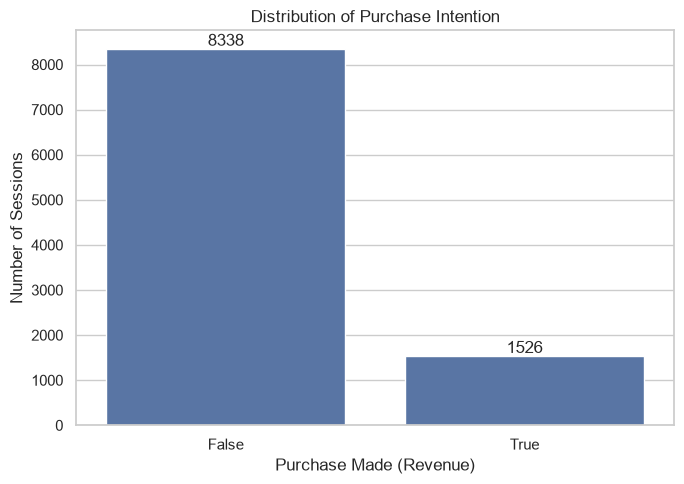

In [42]:

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=train_df,
    x="Revenue"
)

plt.title("Distribution of Purchase Intention")
plt.xlabel("Purchase Made (Revenue)")
plt.ylabel("Number of Sessions")

# Display counts above the bars
for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()


Step 1: Analyze numerical feature distributions

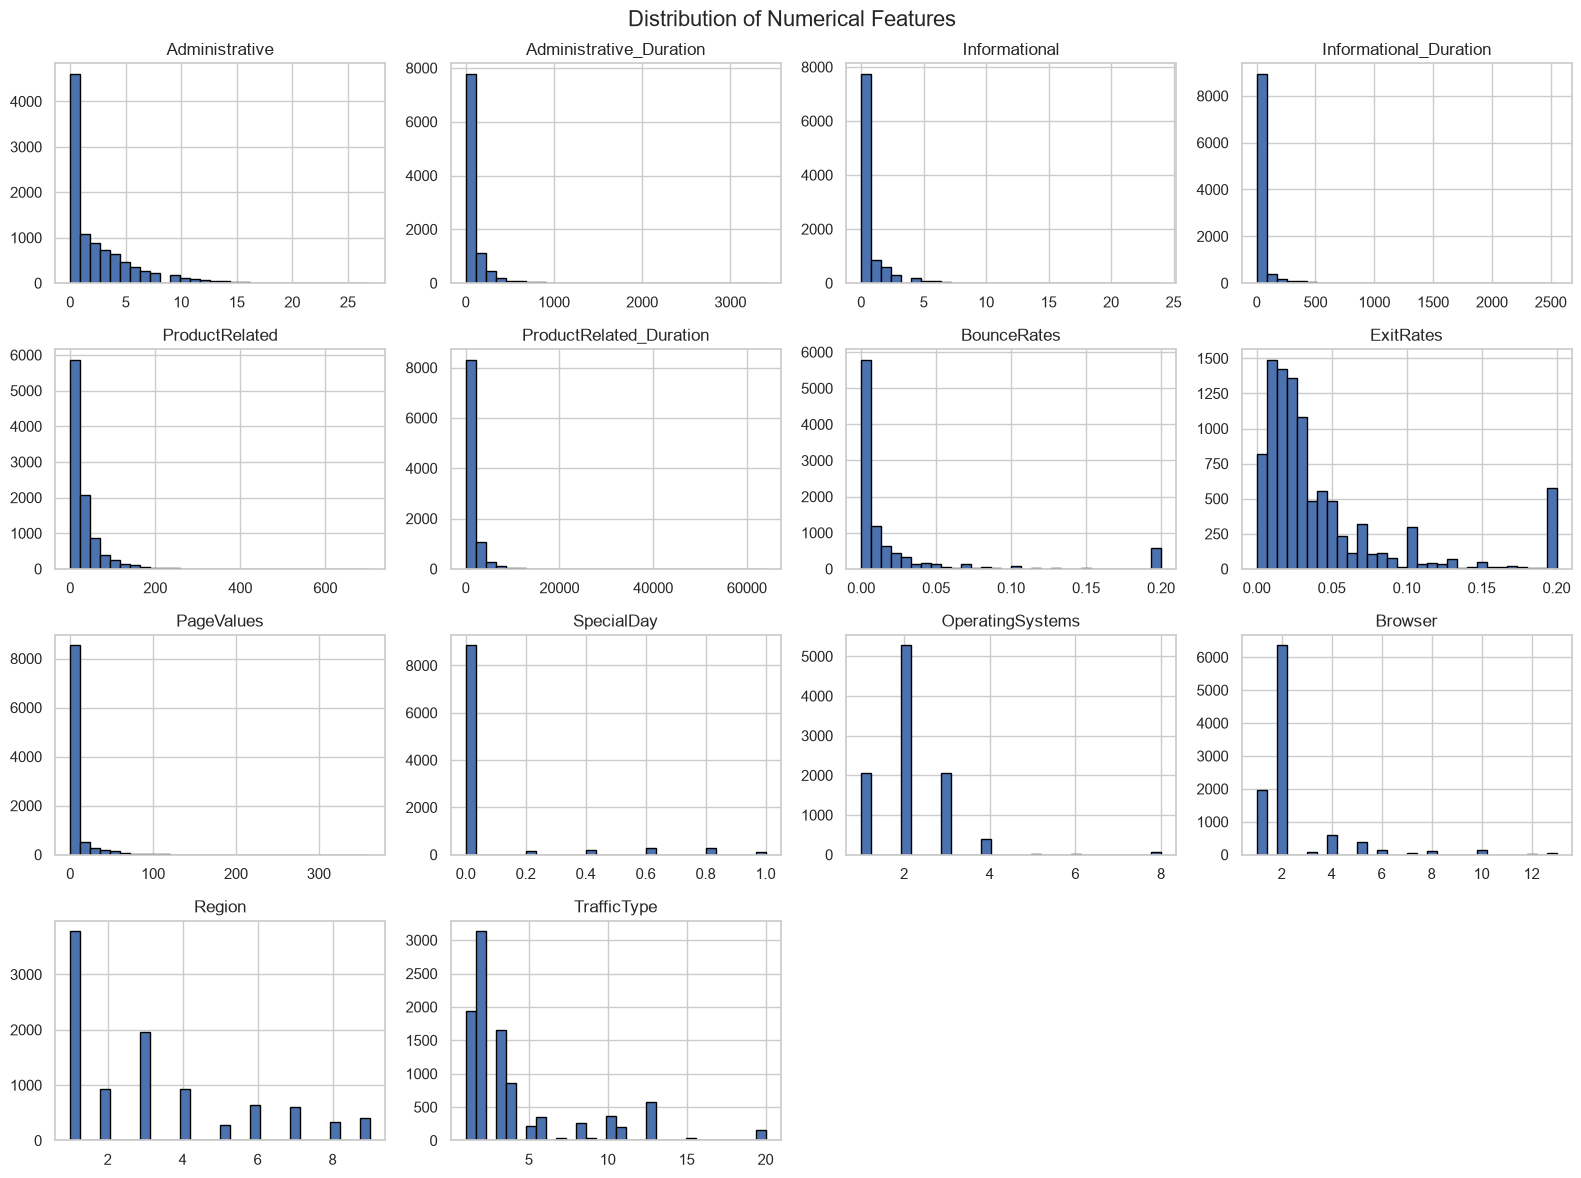

In [43]:

# Select numerical columns
numeric_df = train_df.select_dtypes(include="number")

# Plot histograms
numeric_df.hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()


Step 2: Analyze categorical features

In [44]:

categorical_cols = [
    "Month",
    "VisitorType",
    "Weekend",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType"
]

for col in categorical_cols:
    print(f"\nValue counts for {col}:")
    print(train_df[col].value_counts())



Value counts for Month:
Month
May     2703
Nov     2360
Mar     1538
Dec     1391
Oct      444
Sep      368
Jul      344
Aug      342
June     228
Feb      146
Name: count, dtype: int64

Value counts for VisitorType:
VisitorType
Returning_Visitor    8443
New_Visitor          1347
Other                  74
Name: count, dtype: int64

Value counts for Weekend:
Weekend
False    7578
True     2286
Name: count, dtype: int64

Value counts for OperatingSystems:
OperatingSystems
2    5275
1    2063
3    2050
4     383
8      67
6      17
5       5
7       4
Name: count, dtype: int64

Value counts for Browser:
Browser
2     6361
1     1959
4      596
5      382
6      140
10     135
8      107
3       83
13      52
7       36
12       7
11       5
9        1
Name: count, dtype: int64

Value counts for Region:
Region
1    3782
3    1951
4     937
2     924
6     643
7     606
9     413
8     337
5     271
Name: count, dtype: int64

Value counts for TrafficType:
TrafficType
2     3135
1     1934


Step 3: Create a correlation heatmap

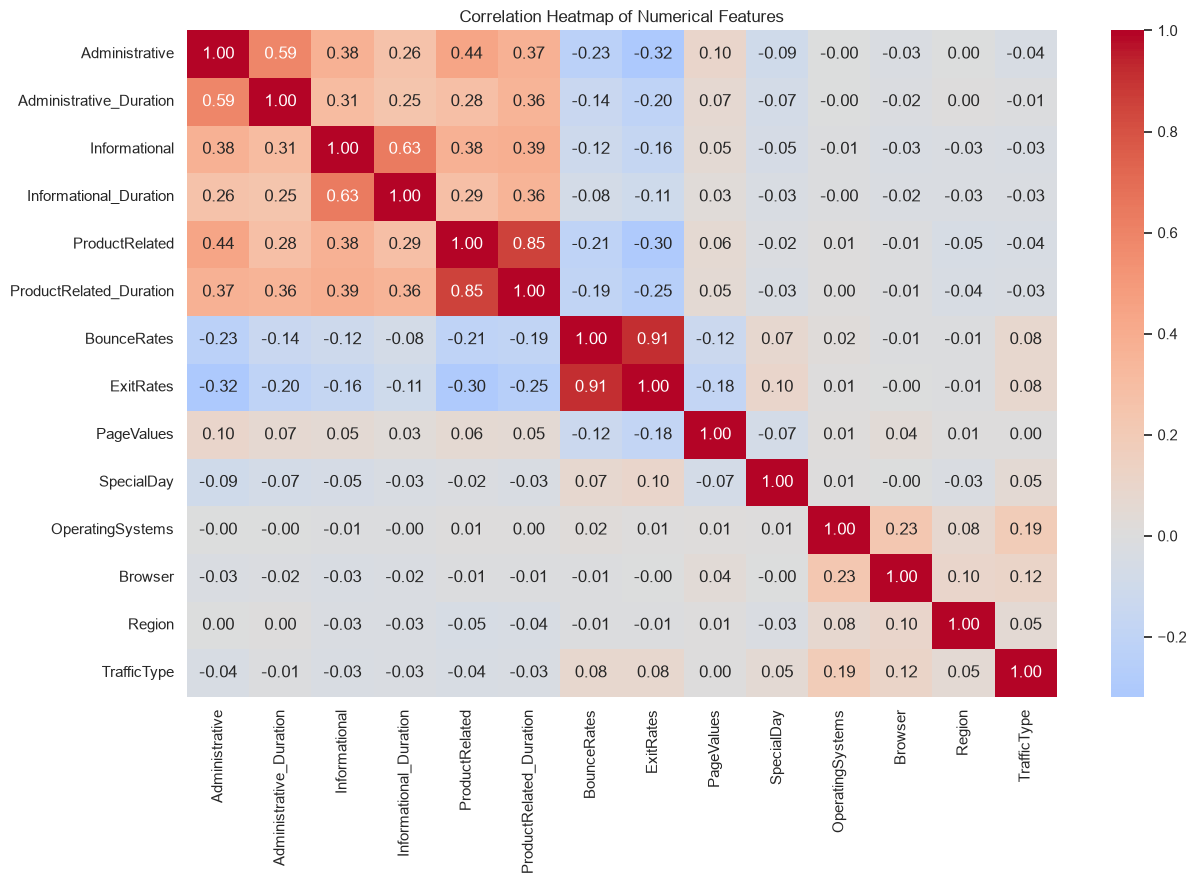

In [45]:

numeric_df = train_df.select_dtypes(include="number")

plt.figure(figsize=(13, 9))

sns.heatmap(
    numeric_df.corr(),
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()


Step 4: Explore relationships between features and Revenue

4.1 Compare PageValues by Revenue

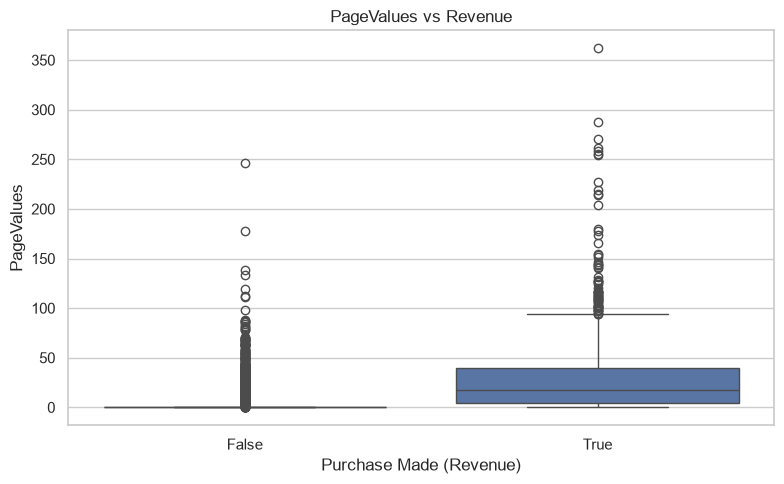

In [46]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=train_df,
    x="Revenue",
    y="PageValues"
)

plt.title("PageValues vs Revenue")
plt.xlabel("Purchase Made (Revenue)")
plt.ylabel("PageValues")

plt.tight_layout()
plt.show()


4.2 Compare ProductRelated_Duration by Revenue

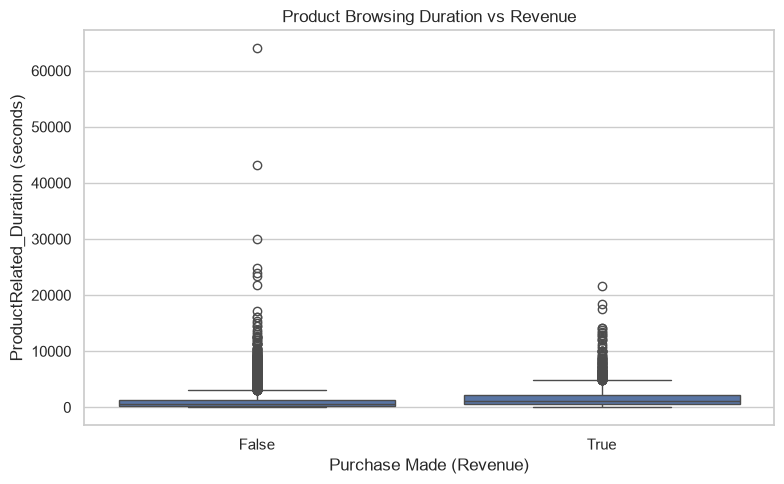

In [49]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=train_df,
    x="Revenue",
    y="ProductRelated_Duration"
)

plt.title("Product Browsing Duration vs Revenue")
plt.xlabel("Purchase Made (Revenue)")
plt.ylabel("ProductRelated_Duration (seconds)")

plt.tight_layout()
plt.show()


## EDA Findings

1. **Dataset structure:** The dataset has 18 columns: 17 input features and the target, `Revenue`. The features include numerical measures such as page counts and durations, and categorical features such as `Month`, `VisitorType`, and `Weekend`.

2. **Missing values:** The check found no missing values.

3. **Duplicate rows:** The check found no duplicate rows.

4. **Target distribution:** `Revenue` is imbalanced: non-purchase sessions are more common than purchase sessions. This should be considered when evaluating models; accuracy alone may not give a complete picture.

5. **Numerical features:** The histograms suggest that several page-duration features are right-skewed, with many short sessions and a smaller number of long ones. `SpecialDay` and some rate-related features have many values near zero. `PageValues` is also zero for many sessions and has a long upper tail. These patterns suggest potential outliers and may influence models sensitive to feature distributions.

6. **Categorical features:** The value counts show that some categories occur much more often than others. In particular, `VisitorType` and `Weekend` have dominant categories, while several numeric-coded categories (such as `Browser`, `Region`, and `TrafficType`) have uneven frequencies. Check the printed value counts for the exact most frequent category in this dataset.

7. **Feature relationships:** The correlation heatmap can highlight related numerical features; for example, browsing page counts and their durations may be associated, as may `BounceRates` and `ExitRates`. The boxplots show that sessions resulting in a purchase tend to have higher `PageValues` and often greater `ProductRelated_Duration`, though the distributions overlap and include outliers. These are associations, not proof of cause.

8. **Preprocessing implications:** Encode categorical features before fitting models. Since fields such as `OperatingSystems`, `Browser`, `Region`, and `TrafficType` are category labels rather than continuous measurements, one-hot encoding is generally appropriate. Scale numerical features for scale-sensitive models such as logistic regression, SVM, and KNN; scaling is usually unnecessary for tree-based models. Because the target classes are imbalanced, consider stratified splits and metrics such as precision, recall, F1-score, and ROC-AUC, alongside accuracy.